# Figure 1 — Benchmark design and data landscape

What goes *into* the benchmark: the three data regimes, the datasets, where they sit on the confounding axis, the simulation grid, and the method inventory. No results.

**Each panel is defined and drawn in its own cell.** Edit the function, re-run that one cell, see the result. The last cell assembles all of them at the submission size (180 x 230 mm) and writes the PDF that goes to the journal.

Run the Setup, Shared helpers and Data cells first; after that the panel cells are independent of each other.

## Setup

In [1]:
# Everything the panels read is relative to benchmark/, so make that the working directory
# whether the notebook was opened from benchmark/ or from benchmark/figures/.
if (basename(getwd()) == "figures") setwd("..")
stopifnot("run this from benchmark/ or benchmark/figures/" = file.exists("config/methods.tsv"))

# _panels.R holds what every figure shares: the method inventory and its ordering, the metric
# catalogue, the two normalisations used for ranking, the theme, and save_figure().
source("figures/_panels.R")
suppressMessages(library(ggrepel))

results_dir <- "results"

## Shared helpers

Small pieces more than one panel below needs.

In [2]:
dataset_confounding_table <- function(datasets, results_dir)
  dataset_confounding(results_dir, sub("^results/data/", "", datasets$path))

## Data

In [3]:
datasets <- read.delim("data/DATASETS.tsv")
datasets <- datasets[datasets$track %in% c("real", "mock"), ]
scenarios <- read.delim("config/scenarios.tsv")
methods <- method_table()
methods <- methods[methods$role != "sensitivity", ]
confounding <- dataset_confounding_table(datasets, results_dir)

cat(nrow(datasets), "datasets,", nrow(scenarios), "scenarios,", nrow(methods), "methods\n")

13 datasets, 213 scenarios, 17 methods


## a. Design schematic

Three data regimes feed one wrapper interface; four metric families read its output. Drawn with elbow connectors so no two arrows cross.

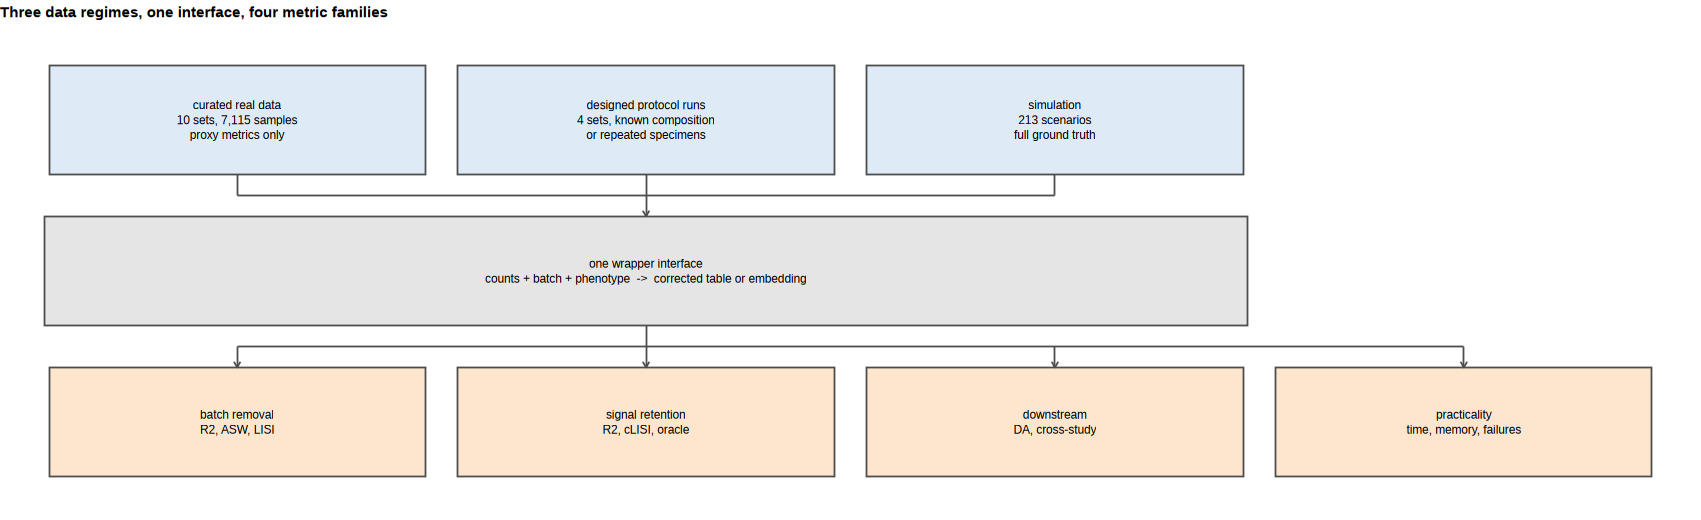

In [4]:
panel_design <- function() {
  boxes <- data.frame(
    x = c(1, 2, 3, 2, 1, 2, 3, 4), y = c(3, 3, 3, 2, 1, 1, 1, 1),
    fill = c(rep("regime", 3), "interface", rep("metric", 4)),
    text = c("curated real data\n10 sets, 7,115 samples\nproxy metrics only",
             "designed protocol runs\n4 sets, known composition\nor repeated specimens",
             "simulation\n213 scenarios\nfull ground truth",
             "one wrapper interface\ncounts + batch + phenotype  ->  corrected table or embedding",
             "batch removal\nR2, ASW, LISI", "signal retention\nR2, cLISI, oracle",
             "downstream\nDA, cross-study", "practicality\ntime, memory, failures"))
  boxes$width <- ifelse(boxes$fill == "interface", 2.94, 0.92)
  # Elbow connectors rather than a fan of diagonals: every box drops straight onto a horizontal bus,
  # so no two lines cross and the arrowheads do not pile up on one point.
  tall <- 0.72; half <- tall / 2; tip <- arrow(length = unit(1.1, "mm"))
  ggplot(boxes, aes(x, y)) +
    geom_tile(aes(fill = fill, width = width), height = tall, colour = "grey30", linewidth = 0.3) +
    geom_text(aes(label = text), size = 1.9, lineheight = 1.1) +
    annotate("segment", x = c(1, 3, 1), xend = c(1, 3, 3), y = c(3 - half, 3 - half, 2.5),
             yend = 2.5, linewidth = 0.3, colour = "grey30") +
    annotate("segment", x = 2, xend = 2, y = 3 - half, yend = 2 + half,
             arrow = tip, linewidth = 0.3, colour = "grey30") +
    annotate("segment", x = c(2, 1), xend = c(2, 4), y = c(2 - half, 1.5), yend = 1.5,
             linewidth = 0.3, colour = "grey30") +
    annotate("segment", x = 1:4, xend = 1:4, y = 1.5, yend = 1 + half,
             arrow = tip, linewidth = 0.3, colour = "grey30") +
    scale_fill_manual(values = c(regime = "#deebf7", interface = "grey90", metric = "#fee6ce"),
                      guide = "none") +
    scale_x_continuous(expand = expansion(0.02)) +
    coord_cartesian(xlim = c(0.5, 4.5), ylim = c(0.5, 3.5)) +
    labs(title = "Three data regimes, one interface, four metric families") +
    theme_void(base_size = 7) + theme(plot.title = element_text(size = 7, face = "bold"))
}

show_panel(panel_design(), 180, 55)

## b. Dataset landscape

Size against number of batches. Point area is the number of taxa; colour separates the sets that are scored from the three kept for calibration.

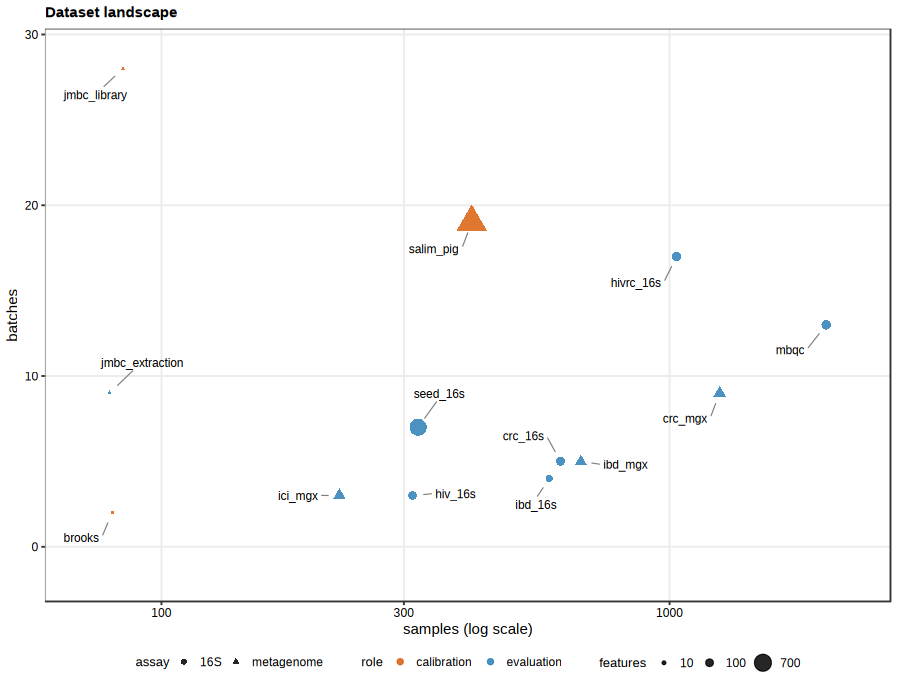

In [5]:
panel_landscape <- function(datasets) {
  ggplot(datasets, aes(samples, n_batch)) +
    geom_point(aes(size = features, shape = assay, colour = evaluated), alpha = 0.85) +
    geom_text_repel(aes(label = dataset), size = 1.9, min.segment.length = 0, max.overlaps = Inf,
                    force = 25, force_pull = 0.3, box.padding = 0.6, point.padding = 0.3,
                    max.iter = 100000, seed = 3,
                    segment.size = 0.2, segment.colour = "grey50") +
    scale_x_log10(expand = expansion(0.09)) +
    # extra room below: four of the datasets sit in one cluster near the bottom of the panel and
    # their labels have nowhere else to go
    scale_y_continuous(expand = expansion(mult = c(0.2, 0.09))) +
    scale_size_area(max_size = 5, breaks = c(10, 100, 700)) +
    scale_colour_manual(values = c(yes = "#2c7fb8", no = "#d95f0e"),
                        labels = c(yes = "evaluation", no = "calibration")) +
    labs(x = "samples (log scale)", y = "batches", size = "features",
         shape = "assay", colour = "role", title = "Dataset landscape") +
    guides(shape = guide_legend(order = 1), colour = guide_legend(order = 2),
           size = guide_legend(order = 3)) +
    theme_bench() +
    # the three legends sit on one line, so they need a gap wide enough that "metagenome" and the
    # next legend's title do not read as one phrase
    theme(legend.position = "bottom", legend.box = "horizontal", legend.title = element_text(size = 6),
          legend.spacing.x = unit(6, "mm"))
}

show_panel(panel_landscape(datasets), 95, 72)

## c. Confounding axis

Where each real dataset falls on Cramer's V, against the five levels the simulation sweeps. mbqc at 0 is the fully crossed anchor.

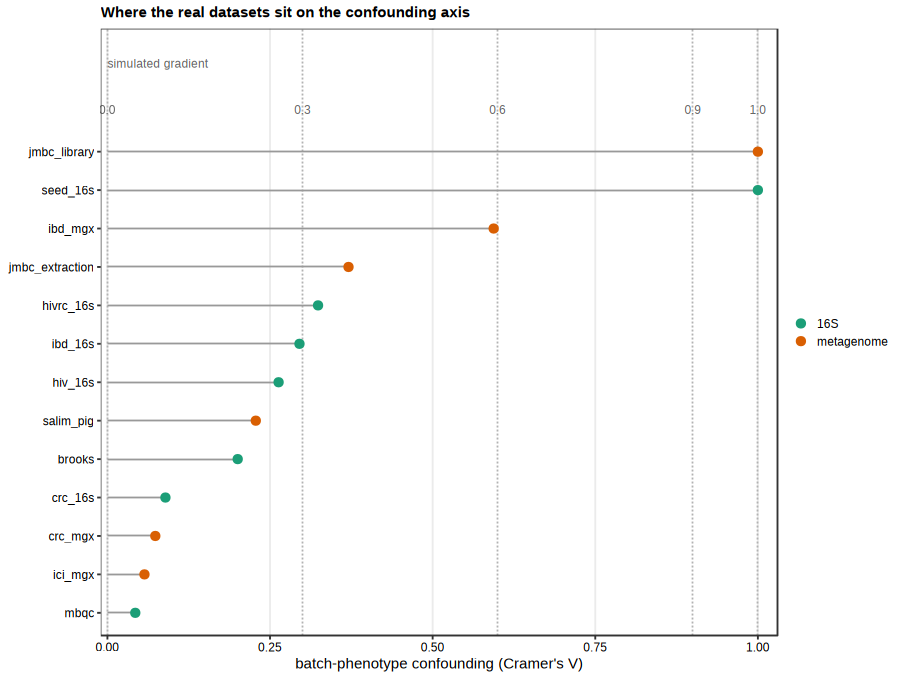

In [6]:
panel_confounding <- function(datasets, confounding, simulated_levels) {
  placed <- data.frame(dataset = datasets$dataset, v = confounding, assay = datasets$assay,
                       evaluated = datasets$evaluated)
  placed$dataset <- factor(placed$dataset, placed$dataset[order(placed$v)])
  ggplot(placed, aes(v, dataset)) +
    geom_vline(xintercept = simulated_levels, colour = "grey70", linetype = "22", linewidth = 0.3) +
    annotate("text", x = simulated_levels, y = nlevels(placed$dataset) + 1.1,
             label = format(simulated_levels), size = 1.9, colour = "grey40") +
    annotate("text", x = 0, y = nlevels(placed$dataset) + 2.3, label = "simulated gradient",
             size = 2, colour = "grey40", hjust = 0) +
    geom_segment(aes(x = 0, xend = v, yend = dataset), colour = "grey60", linewidth = 0.3) +
    geom_point(aes(colour = assay), size = 1.6) +
    scale_colour_brewer(palette = "Dark2") +
    # declared so the numeric y of the two annotations does not type the axis as continuous first
    scale_y_discrete(expand = expansion(add = c(0.6, 3.2))) +
    scale_x_continuous(limits = c(0, 1.02), expand = expansion(0.01)) +
    labs(x = "batch-phenotype confounding (Cramer's V)", y = NULL, colour = NULL,
         title = "Where the real datasets sit on the confounding axis") +
    theme_bench() + theme(panel.grid.major.y = element_blank())
}

show_panel(panel_confounding(datasets, confounding, c(0, 0.3, 0.6, 0.9, 1)), 95, 72)

## d. Simulation parameter space

One strip per factor, one point per scenario: what the 213-scenario grid actually covers.

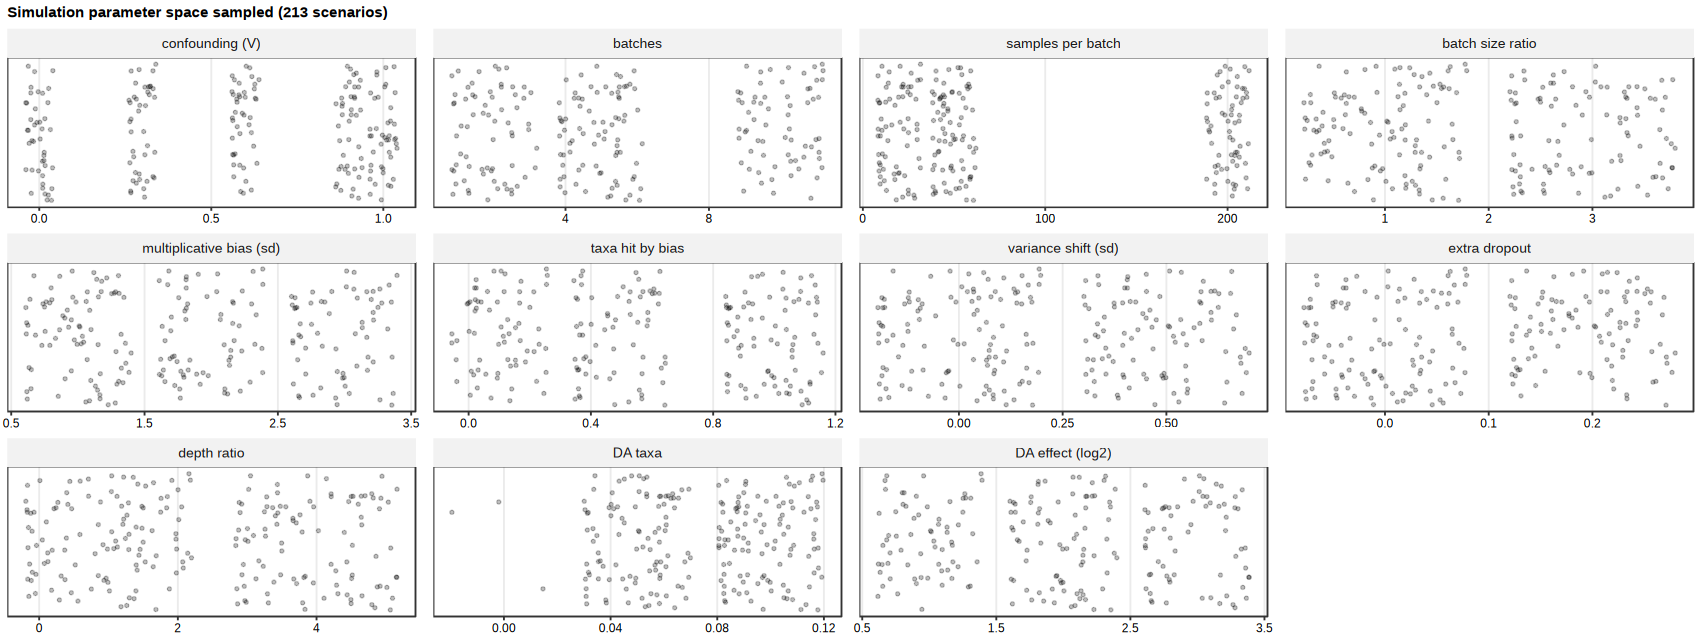

In [7]:
panel_simulation_space <- function(scenarios) {
  axes <- c(conf = "confounding (V)", n_batch = "batches", n_per = "samples per batch",
            imbalance = "batch size ratio", bias_sd = "multiplicative bias (sd)",
            affected = "taxa hit by bias", scale_sd = "variance shift (sd)",
            dropout = "extra dropout", depth_fold = "depth ratio",
            da_prop = "DA taxa", da_log2fc = "DA effect (log2)")
  sampled <- bind_rows(lapply(names(axes), function(k)
    data.frame(parameter = axes[[k]], value = scenarios[[k]])))
  sampled$parameter <- factor(sampled$parameter, axes)
  ggplot(sampled, aes(value, 1)) +
    geom_point(size = 0.5, alpha = 0.25, position = position_jitter(height = 0.3)) +
    facet_wrap(~ parameter, ncol = 4, scales = "free_x") +
    scale_x_continuous(n.breaks = 4) +
    labs(x = NULL, y = NULL, title = "Simulation parameter space sampled (213 scenarios)") +
    theme_bench() +
    theme(axis.text.y = element_blank(), axis.ticks.y = element_blank(),
          panel.grid.major.y = element_blank(), panel.spacing.x = unit(3, "mm"))
}

show_panel(panel_simulation_space(scenarios), 180, 68)

## e. Method inventory

What each method needs and what it returns.

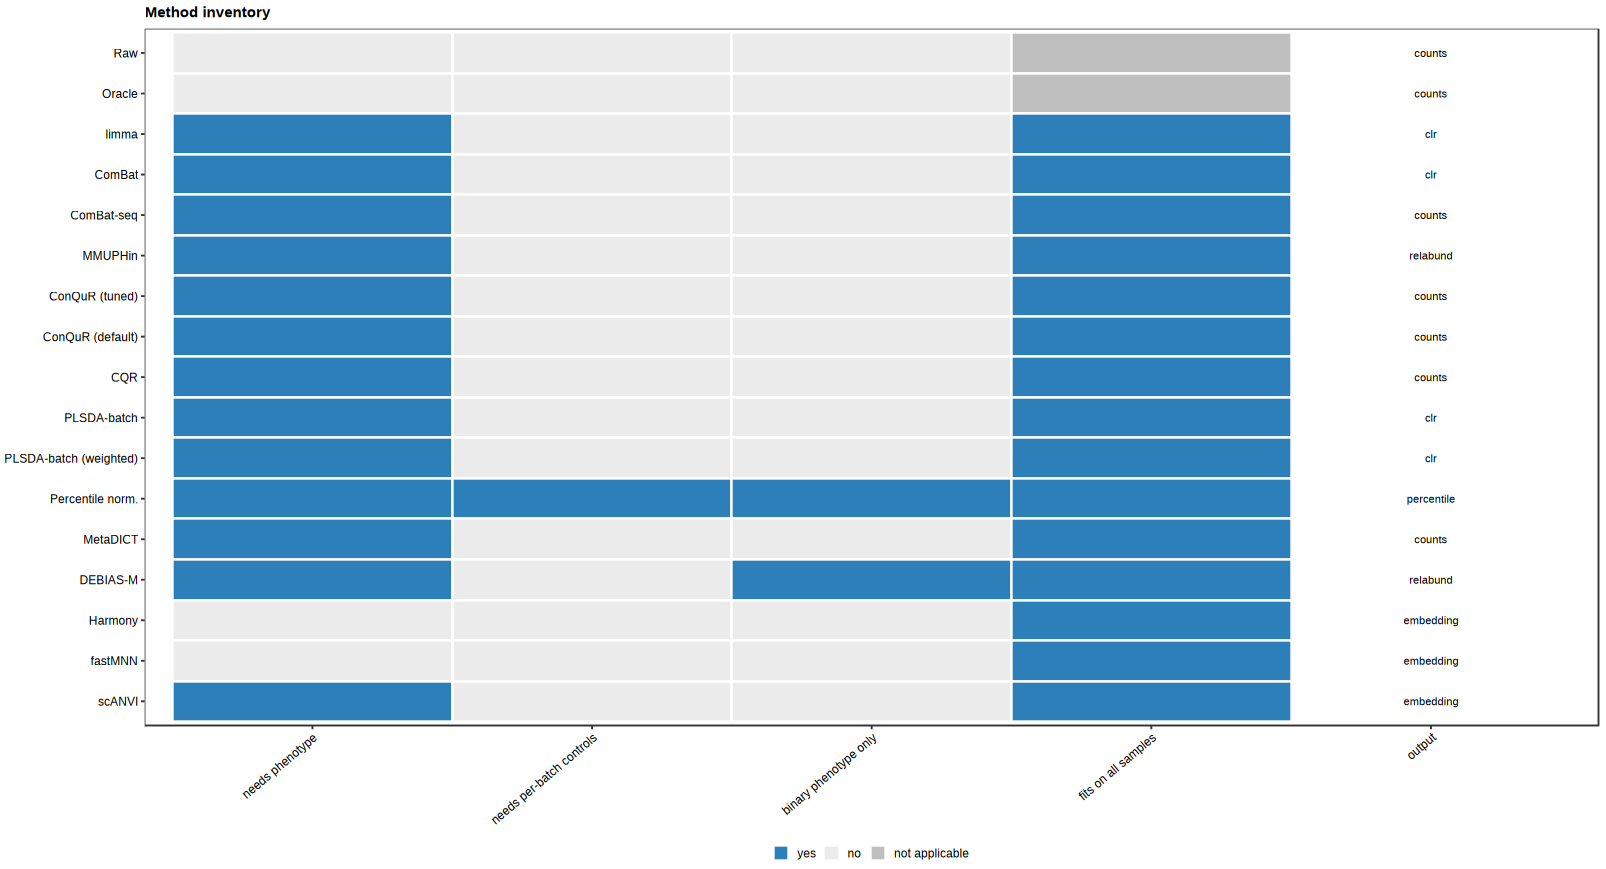

In [8]:
panel_inventory <- function(methods) {
  properties <- c(needs_phenotype = "needs phenotype", needs_controls = "needs per-batch controls",
                  binary_only = "binary phenotype only", transductive = "fits on all samples")
  long <- bind_rows(lapply(names(properties), function(k)
    data.frame(method = methods$method, label = methods$label, track = methods$track,
               property = properties[[k]], value = methods[[k]])))
  long$label <- factor(long$label, rev(methods$label[match(method_order(methods), methods$method)]))
  long$property <- factor(long$property, properties)
  output <- data.frame(label = long$label[!duplicated(long$label)], property = "output",
                       value = methods$output[match(levels(long$label)[as.integer(long$label[!duplicated(long$label)])],
                                                    methods$label)])
  ggplot(long, aes(property, label)) +
    geom_tile(aes(fill = value), colour = "white", linewidth = 0.4) +
    geom_text(data = output, aes(label = value), size = 1.8) +
    scale_fill_manual(values = c(yes = "#2c7fb8", no = "grey92", na = "grey75"), name = NULL,
                      breaks = c("yes", "no", "na"),
                      labels = c(yes = "yes", no = "no", na = "not applicable")) +
    labs(x = NULL, y = NULL, title = "Method inventory") +
    theme_bench() +
    theme(axis.text.x = element_text(angle = 40, hjust = 1), panel.grid = element_blank(),
          legend.position = "bottom")
}

show_panel(panel_inventory(methods), 170, 92)

## Assembled figure

Everything above, in the layout that goes to the journal: 180 x 230 mm, one page.
The panels shrink here — that is the real submission size, and the font sizes above were
chosen for it.

wrote results/figures/fig1.pdf (180 x 230 mm)


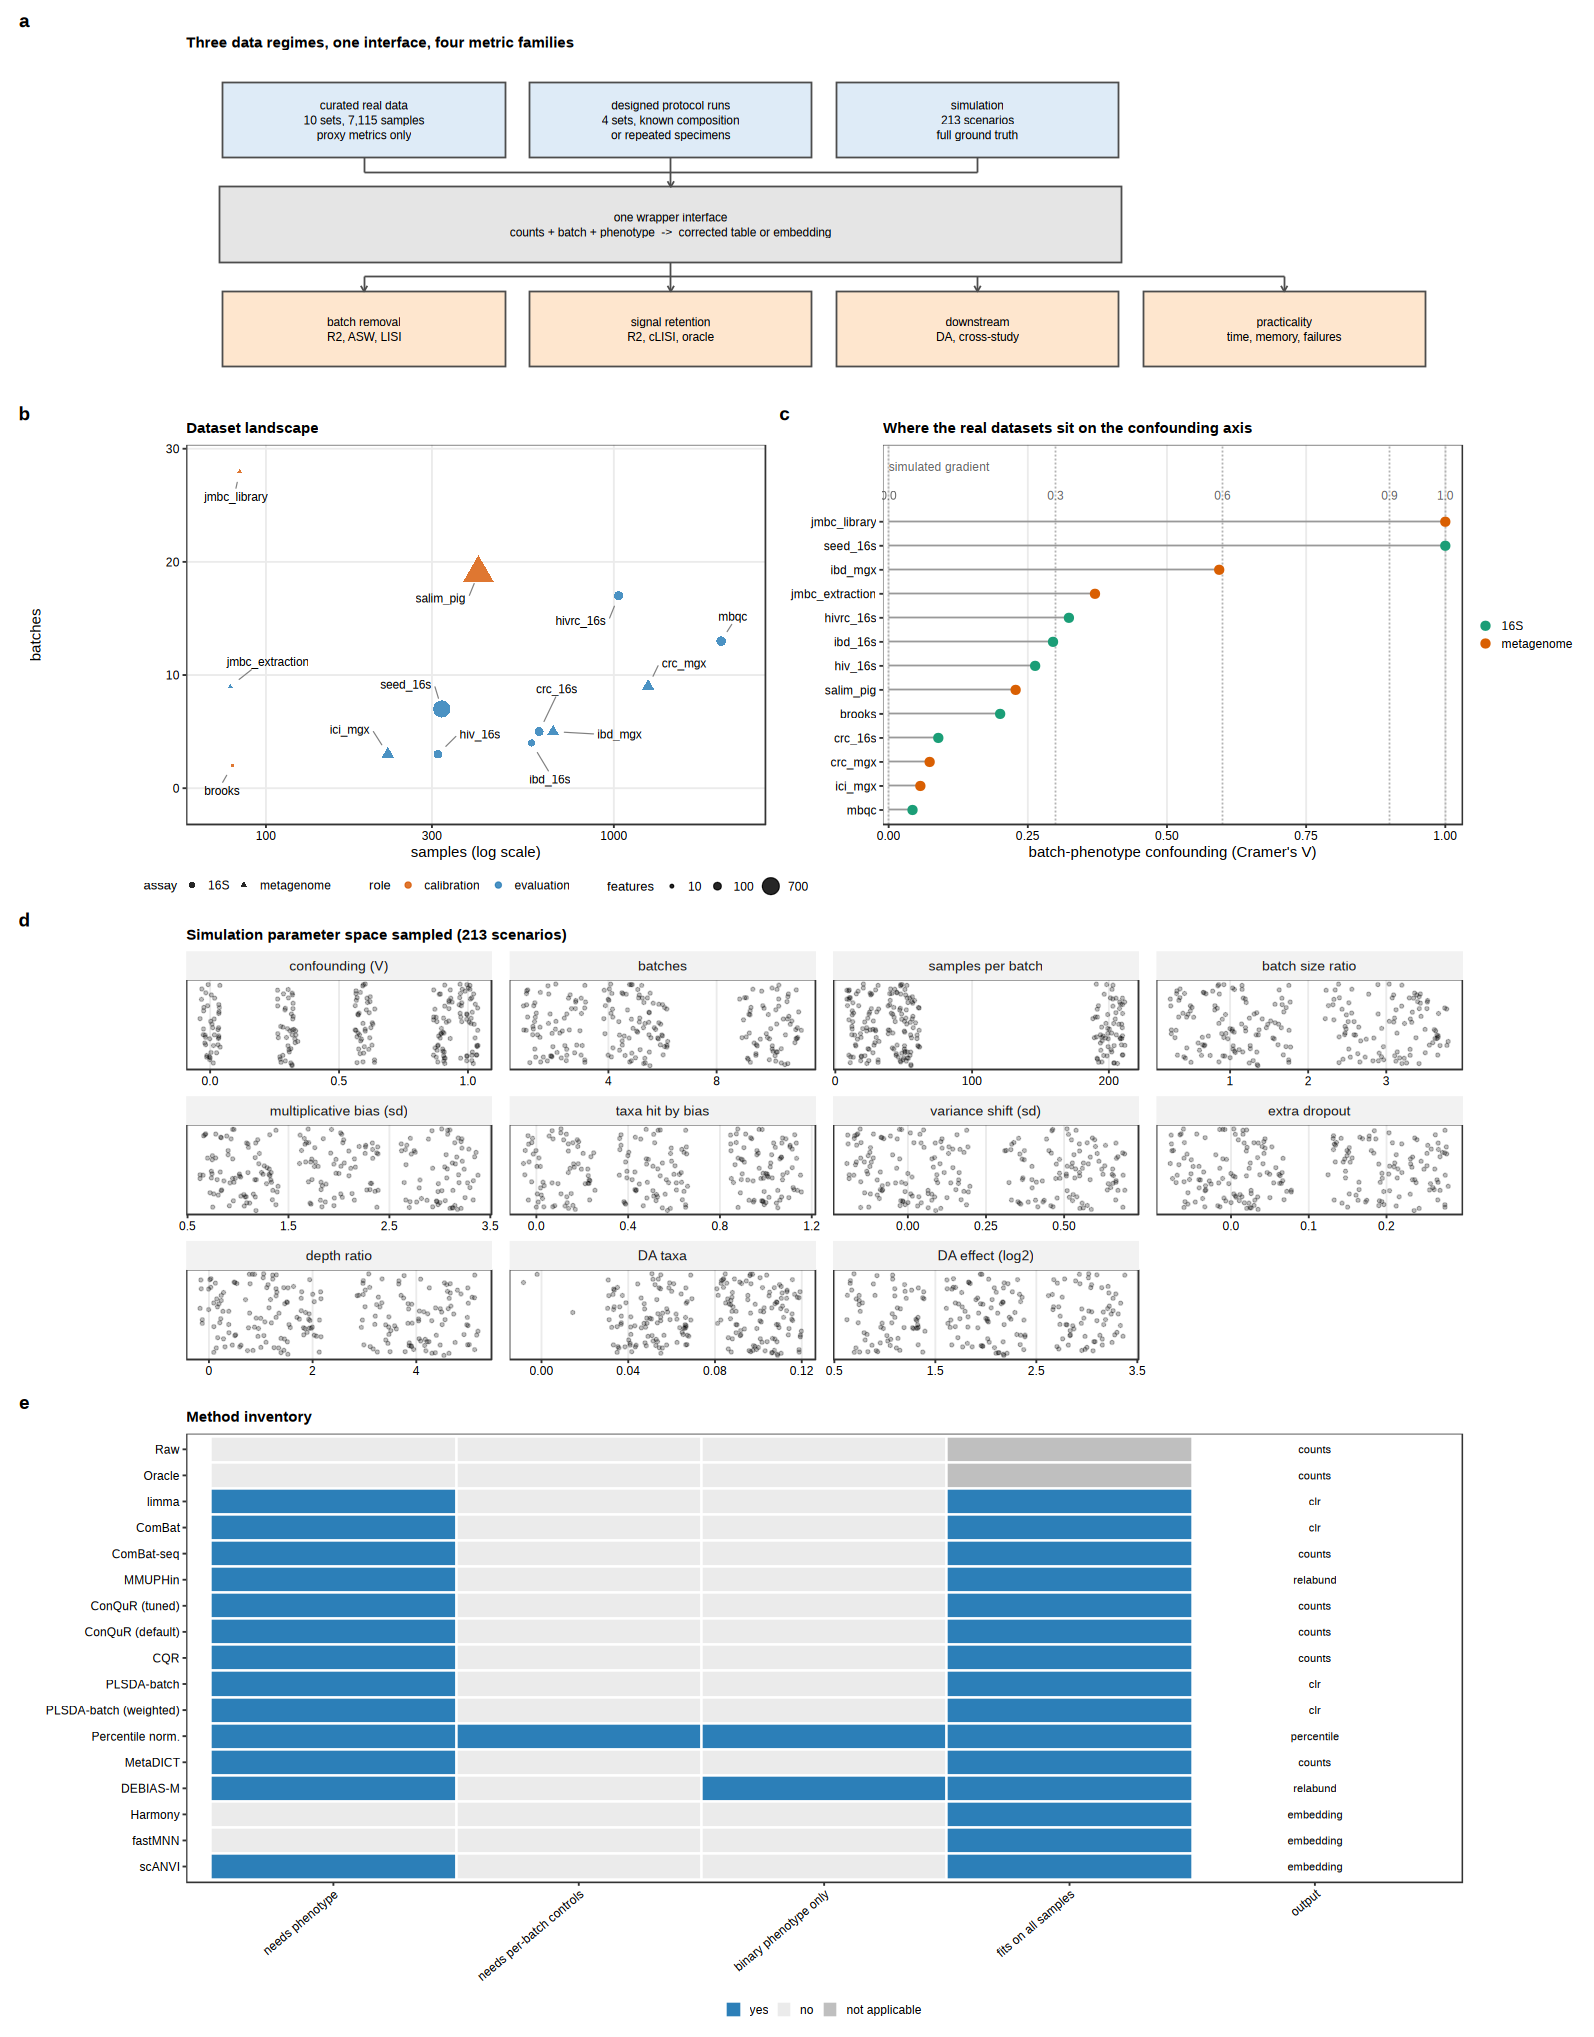

In [9]:
figure <- (panel_design() /
           (panel_landscape(datasets) | panel_confounding(datasets, confounding,
                                                          c(0, 0.3, 0.6, 0.9, 1))) /
           panel_simulation_space(scenarios) /
           panel_inventory(methods)) +
  plot_layout(heights = c(1, 1.1, 1.1, 1.3)) +
  plot_annotation(tag_levels = "a") &
  theme(plot.tag = element_text(size = 9, face = "bold"))

save_figure(figure, "results/figures/fig1.pdf", 180, 230)
show_panel(figure, 180, 230, scale = 1.5)